# 03 · The toric code: a degeneracy that ignores the system size

The control experiment. Run the same machinery on Kitaev's toric code and the answer must be
$\mathrm{GSD}=4$ on every torus. Nothing is derived by hand: the star and plaquette are written as
polynomials, rolled across the torus, and everything physical is read off ranks and kernels.

Two things are new compared with the classical stencils of notebook 02:

* **Two qubits per site and two species of term.** Qubits sit on edges: the $x$-edge and the $y$-edge
  leaving each site. Stars are $X$-type, plaquettes are $Z$-type, so each term is a *vector* of
  polynomials, one per qubit species.
* **The answer is topological, not arithmetic.** It does not depend on $L_x, L_y$, or even on $p$.

In [1]:
import sys
sys.path.insert(0, "..")

import numpy as np
import matplotlib.pyplot as plt
import gsd
from gsd import Poly, ring_mul

TC = gsd.TORIC_CODE
star, plaq = TC.generators
print("star      A_v: X on", [str(f) for f in star.x])
print("plaquette B_p: Z on", [str(f) for f in plaq.z])

star      A_v: X on ['1 - x^-1', '1 - y^-1']
plaquette B_p: Z on ['1 - y', '-1 + x']


## 1. The two stencils

$$A_v=(1-\bar x,\ 1-\bar y)\ \text{on } (X_{x\text{-edge}},X_{y\text{-edge}}),\qquad
  B_p=(1-y,\ x-1)\ \text{on } (Z_{x\text{-edge}},Z_{y\text{-edge}}),$$

with $\bar x=x^{-1}$. The star at $r$ touches the two edges leaving $r$ and the two arriving at it; the
plaquette at $r$ (lower-left corner) circulates around its four edges. Over $GF(2)$ the signs are
invisible; they are kept so that section 6 can rerun everything over $\mathbb Z_p$, where they are what
makes stars and plaquettes commute.

The product of terms $\prod_r A_r^{t_r}$ has $X$-support $(\,(1-\bar x)\,t,\ (1-\bar y)\,t\,)$: rolling, again.

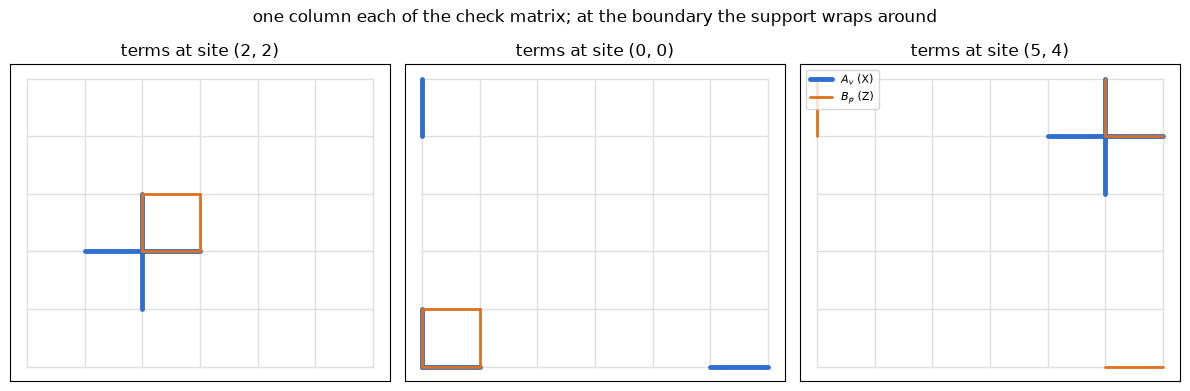

In [2]:
def support(gen_polys, t, p=2):
    """Edge support of prod_r O_r^{t_r}: one ring product per qubit species -> (2, Lx, Ly)."""
    shape = t.shape
    return np.stack([ring_mul(g.on(shape, p), t % p, p) for g in gen_polys])


def draw_lattice(ax, Lx, Ly):
    for i in range(Lx + 1):
        ax.plot([i, i], [0, Ly], color="0.88", lw=1, zorder=0)
    for j in range(Ly + 1):
        ax.plot([0, Lx], [j, j], color="0.88", lw=1, zorder=0)
    ax.set_aspect("equal"), ax.set_xticks([]), ax.set_yticks([])


def draw_support(ax, s, color, lw=3.5, label=None):
    first = True
    for a in range(2):
        for i, j in zip(*np.nonzero(s[a])):
            x1, y1 = (i + 1, j) if a == 0 else (i, j + 1)
            ax.plot([i, x1], [j, y1], color=color, lw=lw, solid_capstyle="round", zorder=3,
                    label=label if first else None)
            first = False


def delta(shape, site):
    d = np.zeros(shape, dtype=np.int64)
    d[site] = 1
    return d


Lx, Ly = 6, 5
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
for ax, site in zip(axes, [(2, 2), (0, 0), (5, 4)]):
    draw_lattice(ax, Lx, Ly)
    draw_support(ax, support(star.x, delta((Lx, Ly), site)), "#2f6fd0", label="$A_v$ (X)")
    draw_support(ax, support(plaq.z, delta((Lx, Ly), site)), "#e0701a", lw=2, label="$B_p$ (Z)")
    ax.set_title(f"terms at site {site}")
ax.legend(loc="upper left", fontsize=8)
fig.suptitle("one column each of the check matrix; at the boundary the support wraps around", y=1.02)
plt.tight_layout()

## 2. The check matrix

One row per term, one column per qubit, $X$ block then $Z$ block: $F$ is $2N\times 4N$ with $N=L_xL_y$.
Before any rank means anything, the terms must commute: for Pauli operators that is the symplectic
condition $F_XF_Z^{\mathsf T}-F_ZF_X^{\mathsf T}\equiv0$.

F has shape (24, 48)   (stars + plaquettes) x (X block + Z block)
all terms commute: True


Text(0.5, 1.0, 'F for the 4×3 torus: stars (top) act with X, plaquettes (bottom) with Z')

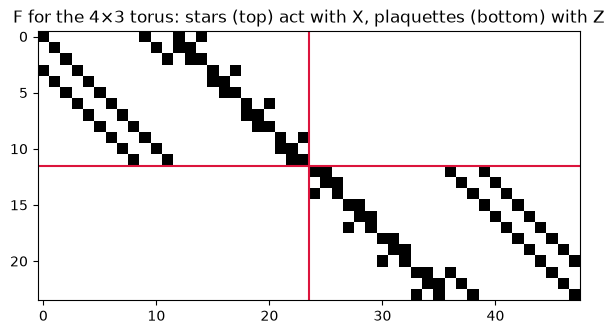

In [3]:
F = TC.check_matrix((4, 3))
N = 12
print("F has shape", F.shape, "  (stars + plaquettes) x (X block + Z block)")
print("all terms commute:", TC.commutes((4, 3)))
plt.figure(figsize=(7, 3.5))
plt.imshow(F, cmap="Greys", interpolation="nearest", aspect="auto")
plt.axhline(N - 0.5, color="crimson"), plt.axvline(2 * N - 0.5, color="crimson")
plt.title("F for the 4×3 torus: stars (top) act with X, plaquettes (bottom) with Z")

## 3. Relations: the whole kernel is two vectors

A relation $\prod_v A_v^{t_v}=\mathbb 1$ needs $(1-\bar x)t=0$ **and** $(1-\bar y)t=0$, so $t$ is
constant along $x$ and along $y$: $t\equiv1$. One relation per species, for every torus:
$\prod_vA_v=\mathbb 1$ and $\prod_pB_p=\mathbb 1$.

In [4]:
for shape in [(4, 3), (5, 5), (6, 2)]:
    T = TC.relations(shape)
    print(f"{shape}: {len(T)} relations; star part of the first one:\n", T[0][: np.prod(shape)].reshape(shape))

(4, 3): 2 relations; star part of the first one:
 [[1 1 1]
 [1 1 1]
 [1 1 1]
 [1 1 1]]
(5, 5): 2 relations; star part of the first one:
 [[1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]]
(6, 2): 2 relations; star part of the first one:
 [[1 1]
 [1 1]
 [1 1]
 [1 1]
 [1 1]
 [1 1]]


## 4. GSD = 4, on every torus

$$\log_2\mathrm{GSD}=n-\operatorname{rank}F = 2N-(N-1)-(N-1)=2 .$$

In general $\log_p\mathrm{GSD}=(n-m)+\dim\ker F^{\mathsf T}$ with $n$ qubits and $m$ terms. The toric code
has $n=m=2N$, so here — and only because of that coincidence — the degeneracy equals the number of
relations. Notebook 05 and section 7 below are cases where it does not.

In [5]:
Ls = range(2, 9)
grid = np.array([[TC.log_gsd((lx, ly), method="brute") for lx in Ls] for ly in Ls])
print(grid)
assert (grid == 2).all()
print("k = 2 on all", grid.size, "tori. The ring agrees without building F:",
      {TC.log_gsd(L) for L in (16, 32, 64, 128)})

[[2 2 2 2 2 2 2]
 [2 2 2 2 2 2 2]
 [2 2 2 2 2 2 2]
 [2 2 2 2 2 2 2]
 [2 2 2 2 2 2 2]
 [2 2 2 2 2 2 2]
 [2 2 2 2 2 2 2]]
k = 2 on all 49 tori. The ring agrees without building F: {2}


Why the ring sees this for every $L$ at once: with one $X$ species,
$\operatorname{rank}F_X=N-\dim R/(1-\bar x,\,1-\bar y)$, and the quotient of $\mathbb F_2[x,y]/(x^{L_x}-1,y^{L_y}-1)$ by
$x=1,\ y=1$ is just $\mathbb F_2$: dimension 1, whatever $L$ is. The stencil factors direction by
direction, the opposite of a fractal stencil.

## 5. Truncating a relation gives the logical operators

The subtle point. A relation applied in full is the identity, not a symmetry. The physical operator
comes from **truncating** it: run the product over a strip only, and what is left over at the edges of
the strip survives. For stars over the first $w$ columns that is two non-contractible loops of $X$ on
the dual lattice; at full width they annihilate.

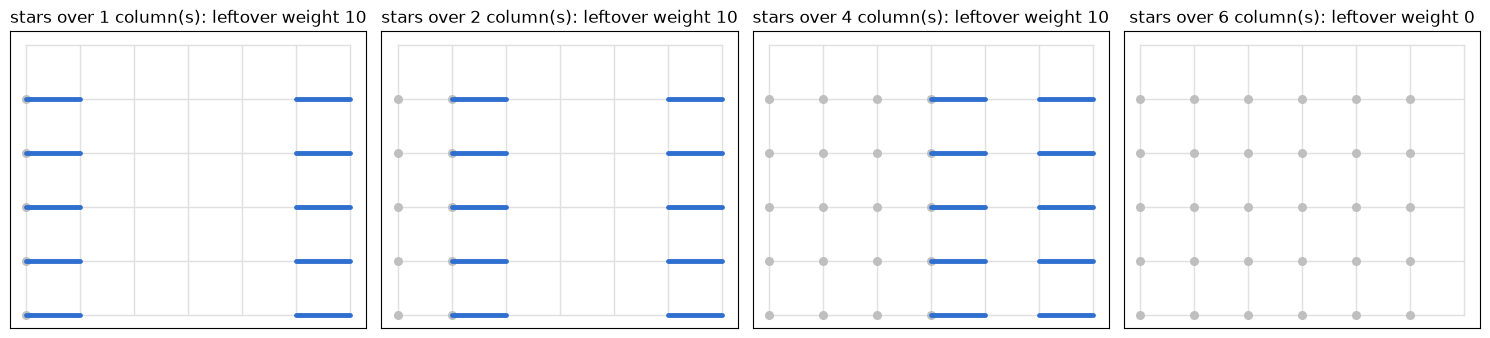

In [6]:
def strip(shape, axis, width):
    t = np.zeros(shape, dtype=np.int64)
    if axis == 0:
        t[:width, :] = 1
    else:
        t[:, :width] = 1
    return t


Lx, Ly = 6, 5
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
for ax, w in zip(axes, [1, 2, 4, Lx]):
    t = strip((Lx, Ly), 0, w)
    s = support(star.x, t)
    draw_lattice(ax, Lx, Ly)
    ax.scatter(*np.nonzero(t), s=30, color="0.75", zorder=2)
    draw_support(ax, s, "#2f6fd0")
    ax.set_title(f"stars over {w} column(s): leftover weight {int((s != 0).sum())}")
plt.tight_layout()

Keeping one boundary of each truncation gives four operators: two directions × two species. Each must
commute with every term, not itself be a product of terms, and pair non-trivially with one partner.
The rank of the pairing matrix is the number of logical qubits: $k=2$ again, from an independent route.

X1: weight 5, commutes with every term: True, is a product of terms: False
X2: weight 6, commutes with every term: True, is a product of terms: False
Z1: weight 6, commutes with every term: True, is a product of terms: False
Z2: weight 5, commutes with every term: True, is a product of terms: False
pairing <Xi, Zj>:
 [[1 0]
 [0 1]] 
k = rank = 2


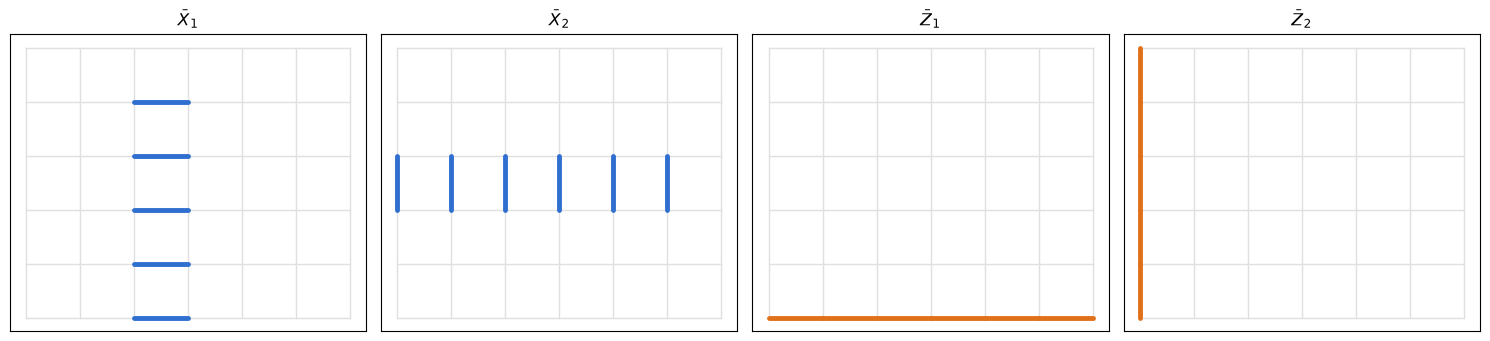

In [7]:
def cut(s, axis, index):
    out = np.zeros_like(s)
    if axis == 0:
        out[:, index, :] = s[:, index, :]
    else:
        out[:, :, index] = s[:, :, index]
    return out


shape = (Lx, Ly)
logicals = {
    "X1": cut(support(star.x, strip(shape, 0, 3)), 0, 2),
    "X2": cut(support(star.x, strip(shape, 1, 3)), 1, 2),
    "Z1": cut(support(plaq.z, strip(shape, 1, 3)), 1, 0),
    "Z2": cut(support(plaq.z, strip(shape, 0, 3)), 0, 0),
}
F = TC.check_matrix(shape)
n = 2 * Lx * Ly
for name, s in logicals.items():
    sym = np.zeros(2 * n, dtype=np.int64)
    sym[(0 if name[0] == "X" else n):][:n] = s.reshape(-1)
    commutes = not ((F[:, :n] @ sym[n:] - F[:, n:] @ sym[:n]) % 2).any()
    is_stabilizer = gsd.rank(np.vstack([F, sym])) == gsd.rank(F)
    print(f"{name}: weight {int(s.sum())}, commutes with every term: {commutes}, is a product of terms: {is_stabilizer}")

pairing = np.array([[int(logicals[f"X{i}"].reshape(-1) @ logicals[f"Z{j}"].reshape(-1)) % 2
                     for j in (1, 2)] for i in (1, 2)])
print("pairing <Xi, Zj>:\n", pairing, "\nk = rank =", gsd.rank(pairing))

fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
for ax, (name, s) in zip(axes, logicals.items()):
    draw_lattice(ax, Lx, Ly)
    draw_support(ax, s, "#2f6fd0" if name[0] == "X" else "#e0701a")
    ax.set_title(f"$\\bar {name[0]}_{name[1]}$")
plt.tight_layout()

## 6. $\mathbb Z_p$ qudits: $\mathrm{GSD}=p^2$

Every function takes `p`. The kernel argument is unchanged over any field ($t$ constant), so the answer
is $p^2$ for every prime and every torus. Compare notebook 02, where changing $p$ changed the *character*
of the six-neighbour answer. Here it only relabels the group: that robustness is what "topological"
means operationally. Without the orientation signs the commutation check fails for $p>2$.

In [8]:
for p in (2, 3, 5, 7):
    for shape in [(3, 3), (5, 4)]:
        k = TC.log_gsd(shape, p, method="brute")
        print(f"p={p}  {shape}: commute {TC.commutes(shape, p)},  GSD = {p}^{k} = {p ** k}")

p=2  (3, 3): commute True,  GSD = 2^2 = 4
p=2  (5, 4): commute True,  GSD = 2^2 = 4
p=3  (3, 3): commute True,  GSD = 3^2 = 9
p=3  (5, 4): commute True,  GSD = 3^2 = 9
p=5  (3, 3): commute True,  GSD = 5^2 = 25
p=5  (5, 4): commute True,  GSD = 5^2 = 25
p=7  (3, 3): commute True,  GSD = 7^2 = 49


p=7  (5, 4): commute True,  GSD = 7^2 = 49


## 7. The 3D toric code, and where "GSD = 2^(number of relations)" breaks

Qubits on the three edges of each site of a cubic lattice, one star per vertex, and three plaquette
species (the $xy$, $yz$, $zx$ faces). The model is four lines with `gsd.Model`. Now $n=3N$ but
$m=4N$, so the degeneracy is *not* the number of relations: the plaquettes satisfy a whole cube's worth
of relations ($\prod_{f\in\partial c}B_f=\mathbb 1$), growing with $L$, while $k$ stays 3.

In [9]:
P = lambda s: Poly(s, dim=3)                       # noqa: E731
zero = P("0")
X3 = gsd.Generator(x=(P("1 - x^-1"), P("1 - y^-1"), P("1 - z^-1")), z=(zero, zero, zero))
Bxy = gsd.Generator(x=(zero,) * 3, z=(P("1 - y"), P("x - 1"), zero))
Byz = gsd.Generator(x=(zero,) * 3, z=(zero, P("1 - z"), P("y - 1")))
Bzx = gsd.Generator(x=(zero,) * 3, z=(P("z - 1"), zero, P("1 - x")))
TC3 = gsd.Model("toric_code_3d", 3, 3, (X3, Bxy, Byz, Bzx))

for shape, p in [((2, 2, 2), 2), ((3, 3, 3), 2), ((3, 2, 4), 2), ((3, 3, 3), 3)]:
    k = TC3.log_gsd(shape, p)
    print(f"{shape} p={p}: commute {TC3.commutes(shape, p)}, relations {len(TC3.relations(shape, p))}, k = {k}")

(2, 2, 2) p=2: commute True, relations 11, k = 3
(3, 3, 3) p=2: commute True, relations 30, k = 3
(3, 2, 4) p=2: commute True, relations 27, k = 3
(3, 3, 3) p=3: commute True, relations 30, k = 3
